In [1]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import onnxruntime as ort
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision.models import mobilenet_v3_small, MobileNet_V3_Small_Weights
from sklearn.model_selection import train_test_split

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# First dataset folder that exists (Windows PC or Linux machine)
DATASET_ROOT = next(p for p in [Path(r"C:/Users/Nils/Downloads/dataset/dataset"),
                                Path.home() / "Desktop/PhysicalAIBinPicking/chudbot/dataset"] if p.exists())

# Classification + centre model (already trained, used as it is)
CLASS_CENTRE_ONNX = next(p for p in [Path("shape_3head_v2.onnx"),
                                     Path.home() / "Desktop/PhysicalAIBinPicking/chudbot/MISC/shape_3head_v2.onnx"]
                         if p.exists())

CLASSES = ["Circle", "Hexagon", "Square", "Star", "Triangle"]          # same order as shape_3head_v2.onnx
SYMMETRY = {"Hexagon": 60, "Square": 90, "Star": 72, "Triangle": 120}  # circles have no rotation
IMG_SIZE = 128
MEAN = np.array([0.485, 0.456, 0.406], np.float32)
STD = np.array([0.229, 0.224, 0.225], np.float32)

print(DEVICE, DATASET_ROOT, CLASS_CENTRE_ONNX)

cpu /home/Nilse/Desktop/PhysicalAIBinPicking/chudbot/dataset /home/Nilse/Desktop/PhysicalAIBinPicking/chudbot/MISC/shape_3head_v2.onnx


In [2]:
def wrap(angle, period):
    """Wrap an angle into [-period/2, period/2)."""
    return (angle + period / 2) % period - period / 2


def get_mask(img):
    """The piece = the biggest bright blob on the black background."""
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    mask = cv2.morphologyEx((gray > 25).astype(np.uint8), cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(mask)
    if n < 2:
        return None
    return labels == 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])


def rule_angle(mask, shape):
    """
    The hard rule. Triangle / star: direction of a tip. Hexagon / square: direction straight out of a flat edge.
    Degrees in the image (x right, y down), so -90 = up. Also returns how well the shape fits (0..1).
    """
    k = 360 // SYMMETRY[shape]
    contours, _ = cv2.findContours(mask.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    outline = max(contours, key=cv2.contourArea)
    corners = cv2.approxPolyDP(outline, 0.02 * cv2.arcLength(outline, True), True).reshape(-1, 2).astype(float)

    if shape in ("Triangle", "Star"):
        m = cv2.moments(outline)
        d = corners - [m["m10"] / m["m00"], m["m01"] / m["m00"]]
        tips = d[np.argsort(np.hypot(d[:, 0], d[:, 1]))[-k:]]      # the k corners furthest from the centre
        angles, weights, extra = np.arctan2(tips[:, 1], tips[:, 0]), np.ones(len(tips)), 0
    else:
        edges = np.roll(corners, -1, axis=0) - corners
        angles, weights, extra = np.arctan2(edges[:, 1], edges[:, 0]), np.hypot(edges[:, 0], edges[:, 1]), 90

    # Average on the k-fold circle, so all the symmetric copies count as the same direction
    z = np.sum(weights * np.exp(1j * k * angles))
    return wrap(np.degrees(np.angle(z)) / k + extra, SYMMETRY[shape]), abs(z) / weights.sum()


def square_canvas(img):
    """Pad to a centred black square, same as vision_v2.py, so resizing doesn't squash the shape."""
    h, w = img.shape[:2]
    side = int(round(max(h, w) * 1.3))
    canvas = np.zeros((side, side, 3), np.uint8)
    y0, x0 = (side - h) // 2, (side - w) // 2
    canvas[y0:y0 + h, x0:x0 + w] = img
    return canvas


def to_tensor(canvas):
    small = cv2.resize(canvas, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    rgb = cv2.cvtColor(small, cv2.COLOR_BGR2RGB).astype(np.float32) / 255
    return torch.from_numpy(((rgb - MEAN) / STD).transpose(2, 0, 1))

In [3]:
df = pd.read_csv(DATASET_ROOT / "labels.csv")
df = df[df["shape"].isin(CLASSES)]

rows = []
for _, r in df.iterrows():
    img = cv2.imread(str(DATASET_ROOT / r["object_masked_path"]))
    mask = get_mask(img)
    if mask is None:
        continue
    angle, fit = rule_angle(mask, r["shape"]) if r["shape"] in SYMMETRY else (0.0, 1.0)
    rows.append({
        "path": r["object_masked_path"],
        "shape": r["shape"],
        "angle": angle,
        "fit": fit,
        "area": mask.sum(),
        "colour": cv2.cvtColor(img, cv2.COLOR_BGR2HSV)[..., 1][mask].mean(),
        "cut_off": mask[0].any() or mask[-1].any() or mask[:, 0].any() or mask[:, -1].any(),
    })
data = pd.DataFrame(rows)

# Remove crops that would teach the network nonsense: paper scraps (grey), clusters / wrong pieces
# (wrong size), pieces cut off at the edge, and outlines that don't look like the shape
size = data["area"] / data.groupby("shape")["area"].transform("median")
good = (data["colour"] > 120) & size.between(0.6, 1.5) & ~data["cut_off"] & (data["fit"] > 0.8)
print(pd.crosstab(data["shape"], good.map({True: "kept", False: "removed"})))
data = data[good].reset_index(drop=True)

col_0     kept  removed
shape                  
Circle      13        0
Hexagon     37       10
Square      32        0
Star        56       24
Triangle    62        6


In [4]:
# Classification (head 1) and centre (head 3) from shape_3head_v2.onnx
class_centre_model = ort.InferenceSession(str(CLASS_CENTRE_ONNX), providers=["CPUExecutionProvider"])


def classify(img):
    """Returns (class, confidence, centre (x, y) in crop pixels)."""
    canvas = square_canvas(img)
    logits, _, centre = class_centre_model.run(None, {"input": to_tensor(canvas).numpy()[None]})
    p = np.exp(logits[0] - logits[0].max())
    p /= p.sum()
    side = canvas.shape[0]
    x0, y0 = (side - img.shape[1]) // 2, (side - img.shape[0]) // 2
    return CLASSES[p.argmax()], p.max(), (centre[0, 0] * side - x0, centre[0, 1] * side - y0)


# Check on the kept crops: class vs label, centre vs the centre of the mask
correct, centre_errors = 0, []
for _, r in data.iterrows():
    img = cv2.imread(str(DATASET_ROOT / r["path"]))
    name, conf, (cx, cy) = classify(img)
    ys, xs = np.nonzero(get_mask(img))
    correct += name == r["shape"]
    centre_errors.append(np.hypot(cx - xs.mean(), cy - ys.mean()))
print(f"classification: {correct}/{len(data)} correct")
print(f"centre: {np.mean(centre_errors):.1f} px off on average")

classification: 200/200 correct
centre: 3.0 px off on average


In [5]:
class RotationDataset(Dataset):
    def __init__(self, df, train):
        self.df = df.reset_index(drop=True)
        self.train = train
        self.images = [square_canvas(cv2.imread(str(DATASET_ROOT / p))) for p in self.df["path"]]

    def __len__(self):
        return len(self.df) * 4                                   # 4 differently turned copies of each crop

    def __getitem__(self, i):
        j = i % len(self.df)
        shape = self.df.at[j, "shape"]
        rng = np.random.default_rng(None if self.train else i)   # validation: same turns every epoch
        img = self.images[j]
        side = img.shape[0]

        # Turn the image by a random angle and the label with it
        # (cv2 turns counter-clockwise on screen, which makes image angles smaller)
        turn = rng.uniform(-180, 180)
        img = cv2.warpAffine(img, cv2.getRotationMatrix2D((side / 2, side / 2), turn, 1.0), (side, side))
        angle = self.df.at[j, "angle"] - turn

        if self.train:
            img = np.clip(img * rng.uniform(0.75, 1.25), 0, 255).astype(np.uint8)   # brightness
            if rng.random() < 0.5:
                img = img[..., rng.permutation(3)].copy()                          # swap colours

        k = 360 // SYMMETRY[shape]
        target = torch.tensor([np.sin(np.radians(k * angle)), np.cos(np.radians(k * angle))], dtype=torch.float32)
        return to_tensor(img), CLASSES.index(shape), target


rotation_data = data[data["shape"].isin(SYMMETRY)]
train_df, val_df = train_test_split(rotation_data, test_size=0.2, random_state=42, stratify=rotation_data["shape"])
train_loader = DataLoader(RotationDataset(train_df, train=True), batch_size=32, shuffle=True)
val_loader = DataLoader(RotationDataset(val_df, train=False), batch_size=64)
print(len(train_df), "train crops |", len(val_df), "val crops")

149 train crops | 38 val crops


In [6]:
class RotationNet(nn.Module):
    """MobileNetV3-small + a small head. Output: one [sin kθ, cos kθ] pair per class, shape (batch, 5, 2)."""

    def __init__(self):
        super().__init__()
        self.features = mobilenet_v3_small(weights=MobileNet_V3_Small_Weights.IMAGENET1K_V1).features
        self.head = nn.Sequential(
            nn.Conv2d(576, 64, kernel_size=1), nn.BatchNorm2d(64), nn.Hardswish(), nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128), nn.Hardswish(), nn.Dropout(0.1),
            nn.Linear(128, len(CLASSES) * 2),
        )

    def forward(self, x):
        return self.head(self.features(x)).view(-1, len(CLASSES), 2)


model = RotationNet().to(DEVICE)

In [7]:
K = torch.tensor([360 // SYMMETRY.get(c, 360) for c in CLASSES], dtype=torch.float32, device=DEVICE)


def pair_for_class(out, cls):
    return out[torch.arange(len(cls)), cls]


def loss_fn(out, cls, target):
    p = pair_for_class(out, cls)
    return (1 - torch.cosine_similarity(p, target)).mean() + 0.1 * ((p.norm(dim=1) - 1) ** 2).mean()


def angle_error(out, cls, target):
    """Error in real degrees, symmetry included."""
    p = pair_for_class(out, cls)
    diff = torch.atan2(p[:, 0], p[:, 1]) - torch.atan2(target[:, 0], target[:, 1])
    diff = torch.atan2(torch.sin(diff), torch.cos(diff))
    return torch.rad2deg(diff.abs()) / K[cls]


@torch.no_grad()
def evaluate(model, loader):
    """Mean angle error per shape."""
    model.eval()
    errors, classes = [], []
    for x, cls, target in loader:
        cls, target = cls.to(DEVICE), target.to(DEVICE)
        errors.append(angle_error(model(x.to(DEVICE)), cls, target).cpu())
        classes.append(cls.cpu())
    errors, classes = torch.cat(errors), torch.cat(classes)
    return {s: errors[classes == CLASSES.index(s)].mean().item() for s in SYMMETRY}

epoch  1 | val error 15.33° | Hexagon 15.8° Square 19.9° Star 18.0° Triangle  7.7°
epoch  2 | val error 11.85° | Hexagon 14.3° Square 13.2° Star 13.4° Triangle  6.5°
epoch  3 | val error  7.67° | Hexagon  7.4° Square 10.4° Star  7.8° Triangle  5.1°
epoch  4 | val error  6.92° | Hexagon  7.4° Square  9.8° Star  6.2° Triangle  4.2°
epoch  5 | val error  4.73° | Hexagon  5.3° Square  5.3° Star  4.7° Triangle  3.6°
epoch  6 | val error  3.60° | Hexagon  2.8° Square  4.8° Star  3.4° Triangle  3.3°
epoch  7 | val error  3.61° | Hexagon  3.0° Square  4.2° Star  4.3° Triangle  3.0°
epoch  8 | val error  2.99° | Hexagon  2.3° Square  3.9° Star  2.8° Triangle  2.9°
epoch  9 | val error  2.65° | Hexagon  2.1° Square  3.3° Star  2.7° Triangle  2.5°
epoch 10 | val error  2.55° | Hexagon  2.3° Square  2.9° Star  2.5° Triangle  2.5°
epoch 11 | val error  2.23° | Hexagon  1.8° Square  2.6° Star  2.2° Triangle  2.2°
epoch 12 | val error  2.67° | Hexagon  3.3° Square  3.1° Star  2.2° Triangle  2.1°
epoc

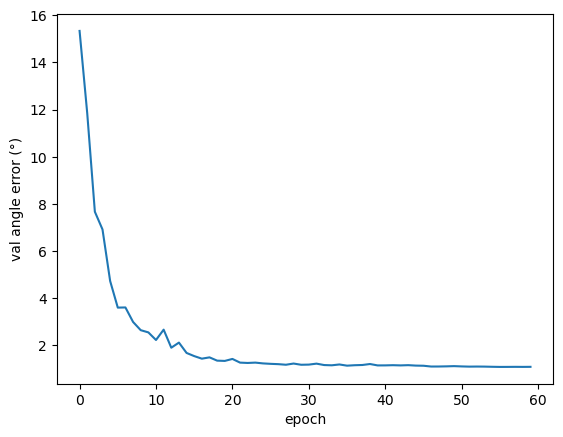

In [8]:
EPOCHS = 60
optimizer = torch.optim.AdamW(model.parameters(), lr=5e-4, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, EPOCHS)

best = float("inf")
history = []
for epoch in range(1, EPOCHS + 1):
    model.train()
    for x, cls, target in train_loader:
        x, cls, target = x.to(DEVICE), cls.to(DEVICE), target.to(DEVICE)
        loss = loss_fn(model(x), cls, target)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    scheduler.step()

    errors = evaluate(model, val_loader)
    mean_error = np.mean(list(errors.values()))
    history.append(mean_error)
    if mean_error < best:
        best = mean_error
        torch.save(model.state_dict(), "best_rotation_net.pth")
    print(f"epoch {epoch:2d} | val error {mean_error:5.2f}° | "
          + " ".join(f"{s} {e:4.1f}°" for s, e in errors.items()))

plt.plot(history)
plt.xlabel("epoch")
plt.ylabel("val angle error (°)")
plt.show()

Hexagon   1.21°
Square    0.79°
Star      1.32°
Triangle  1.03°


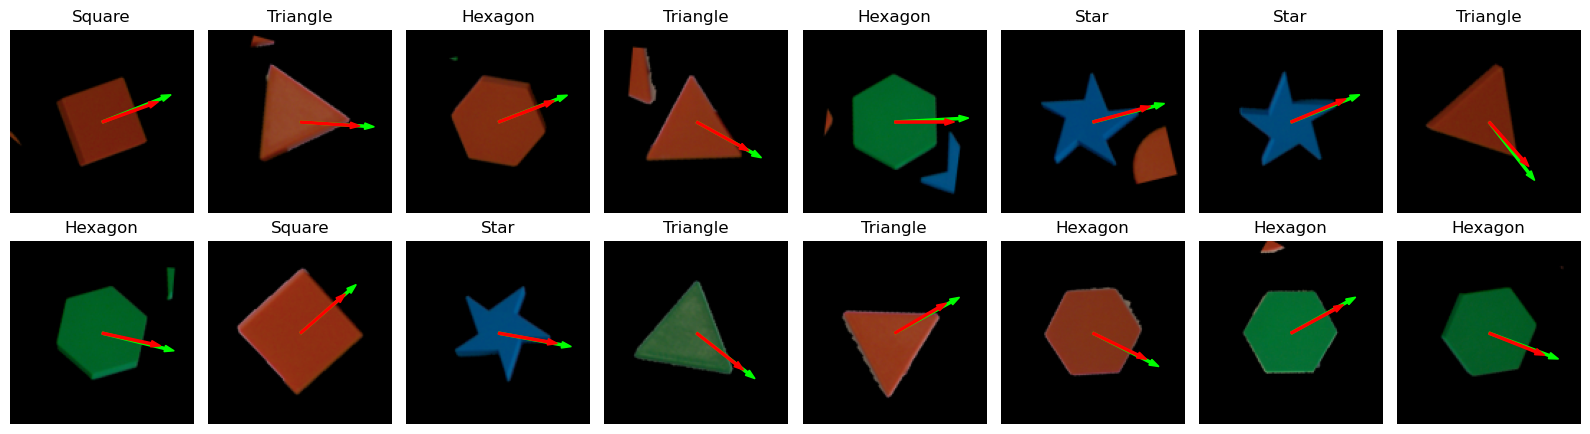

In [9]:
model.load_state_dict(torch.load("best_rotation_net.pth", map_location=DEVICE))
for shape, error in evaluate(model, val_loader).items():
    print(f"{shape:<9} {error:.2f}°")

# Validation crops: green = rule, red = network
val_set = RotationDataset(val_df, train=False)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
model.eval()
for ax, i in zip(axes.flat, np.linspace(0, len(val_set) - 1, 16).astype(int)):
    x, cls, target = val_set[i]
    with torch.no_grad():
        s, c = model(x[None].to(DEVICE))[0, cls].tolist()
    k = K[cls].item()
    for (sin, cos), colour, length in (((target[0].item(), target[1].item()), "lime", 45), ((s, c), "red", 35)):
        a = np.arctan2(sin, cos) / k
        ax.arrow(64, 64, length * np.cos(a), length * np.sin(a), color=colour, width=1.5)
    ax.imshow((x.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1))
    ax.set_title(CLASSES[cls])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [10]:
model.eval().cpu()
torch.onnx.export(model, torch.randn(1, 3, IMG_SIZE, IMG_SIZE), "rotation_net.onnx",
                  input_names=["input"], output_names=["angle_sincos_per_class"],
                  dynamic_axes={"input": {0: "batch"}}, opset_version=17)
print("saved rotation_net.onnx")

saved rotation_net.onnx


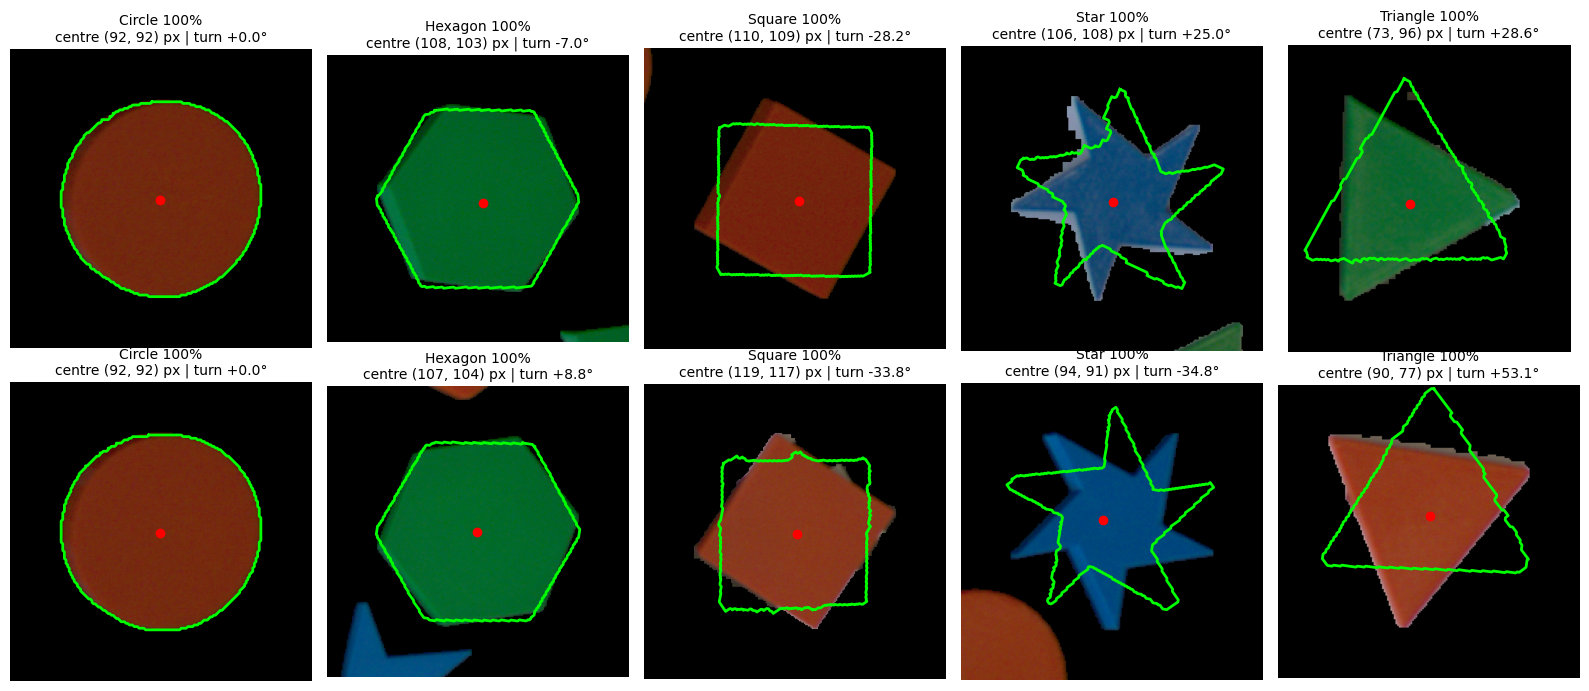

In [11]:
# All three together: class + centre (red dot) + the outline turned into its fixed pose (lime)

rotation_model = ort.InferenceSession("rotation_net.onnx", providers=["CPUExecutionProvider"])


def predict(img):
    """Returns (class, confidence, centre (x, y) in crop pixels, angle in image degrees)."""
    name, conf, centre = classify(img)
    angle = 0.0
    if name in SYMMETRY:
        s, c = rotation_model.run(None, {"input": to_tensor(square_canvas(img)).numpy()[None]})[0][0, CLASSES.index(name)]
        angle = wrap(np.degrees(np.arctan2(s, c)) / (360 // SYMMETRY[name]), SYMMETRY[name])
    return name, conf, centre, angle


def turned_outline(img, centre, turn):
    """The piece's outline turned by `turn` degrees around the centre (+ = clockwise on screen)."""
    contours, _ = cv2.findContours(get_mask(img).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)
    outline = max(contours, key=cv2.contourArea).reshape(-1, 2).astype(float)
    t = np.radians(turn)
    rotation = np.array([[np.cos(t), -np.sin(t)], [np.sin(t), np.cos(t)]])
    return (outline - centre) @ rotation.T + centre


examples = pd.concat([val_df, data[data["shape"] == "Circle"]]).groupby("shape").head(2)   # crops not trained on
fig, axes = plt.subplots(2, 5, figsize=(16, 7))
for ax, (_, r) in zip(axes.T.flat, examples.sort_values("shape").iterrows()):
    img = cv2.imread(str(DATASET_ROOT / r["path"]))
    name, conf, centre, angle = predict(img)
    turn = wrap(-90 - angle, SYMMETRY[name]) if name in SYMMETRY else 0.0   # smallest turn to tip up / flat top
    fixed = turned_outline(img, centre, turn)

    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    ax.plot(*np.vstack([fixed, fixed[:1]]).T, color="lime", linewidth=2)
    ax.plot(*centre, "ro")
    ax.set_title(f"{name} {conf:.0%}\ncentre ({centre[0]:.0f}, {centre[1]:.0f}) px | turn {turn:+.1f}°", fontsize=10)
    ax.axis("off")
plt.tight_layout()
plt.show()